# 레이어 하나: FP32 ↔ 8비트
이미지 한 장에서 **입력 4개·출력 뉴런 2개**만 표시합니다. `psum`은 표시한 네 곱의 누적합이고, `full_sum`은 해당 뉴런의 전체 입력 합입니다. 항목마다 최대 두 줄, 항목 사이는 빈 줄입니다.

기존 분석에서 선택한 표준 정규화를 사용합니다. 앞 레이어는 FP32로 계산하고 **선택한 레이어만 양자화**합니다. 입력·weight·bias·출력은 signed 8비트이며, bias는 부호 확장과 소수점 정렬 후 int32 누산기의 초깃값으로 사용합니다.

출력은 **산술 우측 shift로 하위 비트 버림 → signed 8비트 포화**를 적용합니다. 음수는 0 방향이 아닌 음의 무한대 방향으로 버립니다. 오프라인 입력·weight·bias 양자화의 반올림은 기존 nearest-even을 유지합니다.

표시는 기존처럼 **코드 ÷ 2^F로 복원한 소수 값**입니다. `bias8`은 저장한 값, `bias32`는 누산기 소수점에 정렬한 값입니다. 소스 수정 후에는 커널을 재시작하고 위에서부터 실행합니다.


In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "project/03_model/src/layer_view.py").is_file())
sys.path.insert(0, str(ROOT / "project/03_model"))
from src.layer_view import LayerViewer
viewer = LayerViewer()

## 설정
`LAYER`: fc1/fc2/fc3, `SAMPLE_ID`: test 이미지 번호. 시작 인덱스를 바꾸면 다른 네 입력·두 출력을 봅니다. 소수부는 입력·weight·bias·출력별로 지정합니다. 새 RTL 경로에서는 모두 signed 8비트를 사용합니다.

시작 인덱스는 레이어별 기본값을 두었습니다. 다른 구간을 보려면 해당 숫자를 바꾸거나 정수 하나로 지정하면 됩니다.

입력 F5·weight F7·출력 F2는 기존 하드웨어 초기 설정입니다. `BIAS_FRACS=(9,8,7)`은 기존 bias 범위를 포화 없이 표현하며, 하드웨어 초기값으로 확정했습니다. F9도 **9비트 저장이 아니라 8비트 정수 코드 / 512**를 뜻합니다.


In [2]:
LAYER = "fc1"
SAMPLE_ID = 0
INPUT_START = {"fc1": 201, "fc2": 0, "fc3": 0}[LAYER]
OUTPUT_START = {"fc1": 29, "fc2": 0, "fc3": 0}[LAYER]

INPUT_FRAC = {"fc1": 5, "fc2": 2, "fc3": 2}[LAYER]
WEIGHT_FRAC = 7
OUTPUT_FRAC = 2
BIAS_FRACS = (9, 8, 7)  # FC1, FC2, FC3: 확정한 초기값
BIAS_FRAC = BIAS_FRACS[("fc1", "fc2", "fc3").index(LAYER)]
INPUT_SIGNED = True
OUTPUT_SIGNED = True
OUTPUT_ROUNDING = "truncate"  # 산술 우측 shift로 하위 비트 버림

sample = viewer.select(LAYER, SAMPLE_ID, INPUT_START, OUTPUT_START)


## FP32

In [3]:
float_values = sample.show_float()

fc1 | sample=0 (label=7) | FP32

input [201:205] = [-0.42421296  0.64495873  1.93051040  1.59957635]

weight [29,201:205] = [-0.02551889 -0.01996079 -0.10065302  0.00097796]
weight [30,201:205] = [-0.16407833 -0.04743075  0.05412440  0.09872299]

mul [29] = [ 0.01082545 -0.01287389 -0.19431171  0.00156433]  (input * weight)
mul [30] = [ 0.06960415 -0.03059088  0.10448772  0.15791495]  (input * weight)

psum [29] = [ 0.01082545 -0.00204844 -0.19636014 -0.19479582]  (shown 4 only)
psum [30] = [0.06960415 0.03901327 0.14350100 0.30141595]  (shown 4 only)

full_sum (784 inputs) = [3.49710464 3.77778721]

bias [29:31] = [-0.03533630  0.02314700]

linear = [3.46176839 3.80093431]  (full_sum + bias)
output = [3.46176839 3.80093431]  (ReLU -> layer output)



## 8비트 양자화 후 실제 소수 값

In [4]:
quantized_values = sample.show_quantized(
    input_frac=INPUT_FRAC, weight_frac=WEIGHT_FRAC, output_frac=OUTPUT_FRAC,
    input_signed=INPUT_SIGNED, output_signed=OUTPUT_SIGNED,
    bias_frac=BIAS_FRAC, output_rounding=OUTPUT_ROUNDING,
)


fc1 | sample=0 (label=7) | 8-bit FXP (real values)
input=S8/F5; weight=S8/F7; output=S8/F2; psum=S32/F12; bias=S8/F9

input [201:205] = [-0.43750000  0.65625000  1.93750000  1.59375000]

weight [29,201:205] = [-0.02343750 -0.02343750 -0.10156250  0.00000000]
weight [30,201:205] = [-0.16406250 -0.04687500  0.05468750  0.10156250]

mul [29] = [ 0.01025391 -0.01538086 -0.19677734  0.00000000]  (input * weight)
mul [30] = [ 0.07177734 -0.03076172  0.10595703  0.16186523]  (input * weight)

psum32 [29] = [ 0.01025391 -0.00512695 -0.20190430 -0.20190430]  (shown 4 only)
psum32 [30] = [0.07177734 0.04101562 0.14697266 0.30883789]  (shown 4 only)

full_sum32 (784 inputs) = [3.46215820 3.88989258]

bias8 [29:31] = [-0.03515625  0.02343750]
bias32 [29:31] = [-0.03515625  0.02343750]

acc32 = [3.42700195 3.91333008]  (full_sum + bias)
output8 = [3.25000000 3.75000000]  (ReLU -> requantize)



## 랜덤 이미지 한 장: 입력부터 최종 출력까지
`WEIGHT_FRACS`, `OUTPUT_FRACS`는 각각 **(FC1, FC2, FC3)**의 소수부 비트 수입니다. 모든 입출력은 8비트이며, 앞 레이어의 양자화 출력을 다음 레이어가 그대로 입력받습니다. 출력 숫자는 실제 소수 값으로 표시합니다.

`RANDOM_SEED`가 같으면 같은 이미지로 비교합니다. `None`이면 실행할 때마다 새로 추첨합니다. FC1/FC2는 FP32 출력 절댓값이 큰 뉴런 4개, FC3는 클래스 점수 10개를 표시합니다.

모든 데이터는 signed 8비트입니다. `BIAS_FRACS`와 `OUTPUT_ROUNDING`은 위 설정을 공통으로 사용합니다. Q4.4 예시 뒤 마지막 비교 셀은 입력 F5·weight F7·출력 F2를 사용합니다.


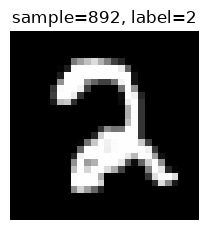

sample=892 | label=2 | FP32 prediction=2 | FXP prediction=2

input [0, 235, 544, 553] FP32 = [-0.42421296  0.40312228  1.82868457  2.82148671]
input S8/F4 FXP = [-0.43750000  0.37500000  1.81250000  2.81250000]

fc1 [274, 341, 349, 455] FP32 = [15.20715809 18.76253891 18.51746559 16.05447197]
fc1 S8/F4 FXP = [7.93750000 7.93750000 7.93750000 7.93750000]

fc2 [12, 33, 61, 111] FP32 = [33.85660553 21.13311768 20.35617828 20.20267677]
fc2 S8/F4 FXP = [7.93750000 7.93750000 7.93750000 7.93750000]

FP32 logits [0:5] = [-7.60383368 -6.22116423 25.53517723 -6.41562557 -8.91451550]
FP32 logits [5:10] = [-15.63866234 -12.46598625   2.05891705  -6.65128899 -20.13497162]

FXP S8/F4 [0:5] = [-5.06250000 -0.81250000  7.93750000 -5.18750000 -3.31250000]
FXP S8/F4 [5:10] = [-8.00000000 -5.93750000  2.25000000 -6.43750000 -8.00000000]



In [5]:
E2E_INPUT_FRAC = 4
WEIGHT_FRACS = (4, 4, 4)  # FC1, FC2, FC3
OUTPUT_FRACS = (4, 4, 4)  # FC1, FC2, FC3
RANDOM_SEED = 42          # None: 실행할 때마다 새로 추첨

end_to_end = viewer.compare_random(
    input_frac=E2E_INPUT_FRAC,
    weight_fracs=WEIGHT_FRACS, output_fracs=OUTPUT_FRACS,
    input_signed=True, hidden_signed=True, output_signed=True,
    bias_fracs=BIAS_FRACS, output_rounding=OUTPUT_ROUNDING,
    seed=RANDOM_SEED,
)

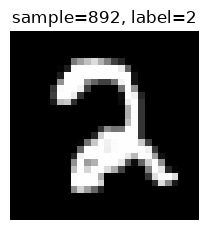

sample=892 | label=2 | FP32 prediction=2 | FXP prediction=2

input [0, 235, 544, 553] FP32 = [-0.42421296  0.40312228  1.82868457  2.82148671]
input S8/F4 FXP = [-0.43750000  0.37500000  1.81250000  2.81250000]

fc1 [274, 341, 349, 455] FP32 = [15.20715809 18.76253891 18.51746559 16.05447197]
fc1 S8/F4 FXP = [7.93750000 7.93750000 7.93750000 7.93750000]

fc2 [12, 33, 61, 111] FP32 = [33.85660553 21.13311768 20.35617828 20.20267677]
fc2 S8/F4 FXP = [7.93750000 7.93750000 7.93750000 7.93750000]

FP32 logits [0:5] = [-7.60383368 -6.22116423 25.53517723 -6.41562557 -8.91451550]
FP32 logits [5:10] = [-15.63866234 -12.46598625   2.05891705  -6.65128899 -20.13497162]

FXP S8/F4 [0:5] = [-5.06250000 -0.81250000  7.93750000 -5.18750000 -3.31250000]
FXP S8/F4 [5:10] = [-8.00000000 -5.93750000  2.25000000 -6.43750000 -8.00000000]



In [6]:
E2E_INPUT_FRAC = 4
WEIGHT_FRACS = (4, 4, 4)  # FC1, FC2, FC3
OUTPUT_FRACS = (4, 4, 4)  # FC1, FC2, FC3
RANDOM_SEED = 42          # None: 실행할 때마다 새로 추첨

end_to_end = viewer.compare_random(
    input_frac=E2E_INPUT_FRAC,
    weight_fracs=WEIGHT_FRACS, output_fracs=OUTPUT_FRACS,
    input_signed=True, hidden_signed=True, output_signed=True,
    bias_fracs=BIAS_FRACS, output_rounding=OUTPUT_ROUNDING,
    seed=RANDOM_SEED,
)

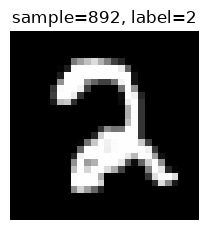

sample=892 | label=2 | FP32 prediction=2 | FXP prediction=2

input [0, 235, 544, 553] FP32 = [-0.42421296  0.40312228  1.82868457  2.82148671]
input S8/F5 FXP = [-0.43750000  0.40625000  1.84375000  2.81250000]

fc1 [274, 341, 349, 455] FP32 = [15.20715809 18.76253891 18.51746559 16.05447197]
fc1 S8/F2 FXP = [15.25000000 18.75000000 18.50000000 16.25000000]

fc2 [12, 33, 61, 111] FP32 = [33.85660553 21.13311768 20.35617828 20.20267677]
fc2 S8/F2 FXP = [31.75000000 21.00000000 20.00000000 20.00000000]

FP32 logits [0:5] = [-7.60383368 -6.22116423 25.53517723 -6.41562557 -8.91451550]
FP32 logits [5:10] = [-15.63866234 -12.46598625   2.05891705  -6.65128899 -20.13497162]

FXP S8/F2 [0:5] = [-7.50000000 -6.50000000 25.00000000 -6.50000000 -8.50000000]
FXP S8/F2 [5:10] = [-15.50000000 -12.25000000   1.50000000  -6.25000000 -19.50000000]



In [7]:
end_to_end = viewer.compare_random(
    input_frac=5,
    weight_fracs=(7, 7, 7),
    output_fracs=(2, 2, 2),
    input_signed=True,
    hidden_signed=True,
    output_signed=True,
    bias_fracs=BIAS_FRACS, output_rounding=OUTPUT_ROUNDING,
    seed=42,
)

## 전체 test 정확도 재확인
바로 위 랜덤 이미지 비교에서 실제 사용한 `end_to_end["config"]`와 **동일한 설정**으로 MNIST test 10,000장을 평가합니다. FP32·8비트 정확도와 차이만 출력합니다. 위 설정을 바꾸면 해당 셀을 먼저 실행한 뒤 이 셀을 실행합니다.

8비트 bias와 출력 하위 비트 버림까지 동일하게 적용합니다. 기존 분석의 분포·weight 오차는 재사용하되, 과거 반올림/int32 bias 정확도를 새 규칙의 정확도로 사용하지 않습니다.


In [8]:
test_result = viewer.evaluate_test(end_to_end["config"], batch_size=512)

MNIST test: 10000 images | device=cuda
S8/F5|W:7,7,7|A:S8/F2,S8/F2,S8/F2|B:S8/F9,S8/F8,S8/F7|ASR

FP32      : 99.32% (9932/10000)
8-bit FXP : 99.29% (9929/10000)

Difference (FXP - FP32): -0.03 percentage points
Predictions changed: 3/10000

